# COVID-19 tweet sentiment: 5-class and 3-class

*Notebook prepared with AI assistance (Claude); I reviewed the results. It mirrors the script in this repo and is for reading the analysis step by step.*

44,955 English tweets (Mar-Apr 2020). The raw CSVs are not committed (licence not verified; tweets may contain personal information), so this notebook has two parts:

1. **Results from the committed `results.json`**, which run without the data and are what the outputs below show.
2. **The full pipeline**, which re-creates them. It runs only if `Corona_NLP_train.csv` and `Corona_NLP_test.csv` are in `data/`.

Method: TF-IDF word uni+bigrams with logistic regression and a linear SVM, tuned by 3-fold CV on the training set only; the test set is scored once. A majority-class baseline is included.

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline

## Part 1. Results from the saved file

In [2]:
R = json.load(open('results.json'))
rows = {}
for task, r in R.items():
    for m in ('majority baseline','LogReg','LinearSVC'):
        rows[(task, m)] = {'accuracy': r[m][0], 'macro-F1': r[m][1]}
sc = pd.DataFrame(rows).T.round(3); sc

accuracy  macro-F1
5-class majority baseline     0.249     0.080
        LogReg                0.542     0.551
        LinearSVC             0.532     0.545
3-class majority baseline     0.407     0.193
        LogReg                0.784     0.752
        LinearSVC             0.784     0.751

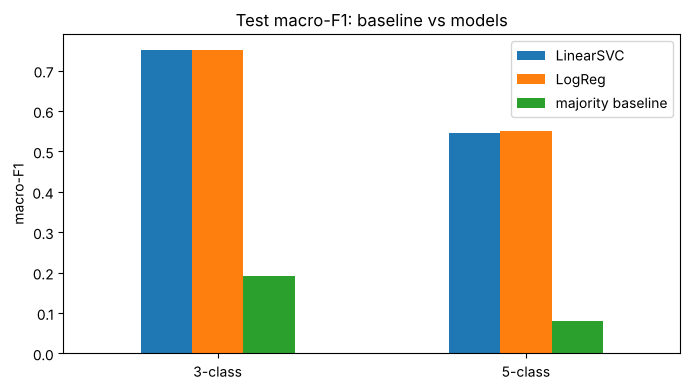

In [3]:
sc['macro-F1'].unstack().plot.bar(figsize=(7,4), title='Test macro-F1: baseline vs models'); plt.ylabel('macro-F1'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [4]:
print('Cross-validated macro-F1 (train only) vs test macro-F1, LogReg:')
for task, r in R.items(): print(f'  {task}: CV {r["LogReg_cv_f1"]:.3f}  test {r["LogReg"][1]:.3f}')

Cross-validated macro-F1 (train only) vs test macro-F1, LogReg:
  5-class: CV 0.563  test 0.551
  3-class: CV 0.750  test 0.752


In [5]:
for task, r in R.items():
    print(task, '- LogReg per-class results')
    display(pd.DataFrame(r['LogReg_report']).T)

5-class - LogReg per-class results


,precision,recall,f1-score
Extremely Negative,0.604,0.471,0.529
Extremely Positive,0.654,0.521,0.580
Negative,0.486,0.513,0.499
Neutral,0.623,0.624,0.623
Positive,0.479,0.578,0.524


3-class - LogReg per-class results


,precision,recall,f1-score
Negative,0.806,0.801,0.803
Neutral,0.699,0.582,0.635
Positive,0.789,0.847,0.817


In [6]:
for task, r in R.items():
    cm = pd.DataFrame(r['confusions']).fillna(0).astype(int)
    print(task, '- confusion matrix (rows = predicted, columns = actual)')
    display(cm)

5-class - confusion matrix (rows = predicted, columns = actual)


,Extremely Negative,Extremely Positive,Negative,Neutral,Positive
Extremely Negative,279,8,257,14,34
Extremely Positive,3,312,34,8,242
Negative,140,24,534,131,212
Neutral,10,9,108,386,106
Positive,30,124,165,81,547


3-class - confusion matrix (rows = predicted, columns = actual)


,Negative,Neutral,Positive
Negative,1308,98,227
Neutral,136,360,123
Positive,179,57,1310


## Part 2. Full pipeline (needs the raw data)

In [7]:
import os
HAVE_DATA = all(os.path.exists('data/'+f) for f in ('Corona_NLP_train.csv','Corona_NLP_test.csv'))
print('raw data found:', HAVE_DATA)

raw data found: False


In [8]:
import numpy as np, re, sys
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report



In [9]:
if HAVE_DATA:
    D = 'data'   # folder holding Corona_NLP_train.csv and Corona_NLP_test.csv
    tr = pd.read_csv(D+'/Corona_NLP_train.csv', encoding='latin1'); te = pd.read_csv(D+'/Corona_NLP_test.csv', encoding='latin1')
    def clean(s):
        s = re.sub(r'https?://\S+', ' url ', s); s = re.sub(r'@\w+', ' @user ', s)
        return re.sub(r'\s+', ' ', s).strip().lower()
    Xtr, Xte = tr.OriginalTweet.map(clean), te.OriginalTweet.map(clean)
    three = lambda s: s.str.replace('Extremely ', '', regex=False)
    out = {}
    for name, ytr, yte in (('5-class', tr.Sentiment, te.Sentiment), ('3-class', three(tr.Sentiment), three(te.Sentiment))):
        res = {}
        d = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr); p = d.predict(Xte)
        res['majority baseline'] = (accuracy_score(yte, p), f1_score(yte, p, average='macro'))
        feats = TfidfVectorizer(ngram_range=(1,2), min_df=3, max_features=60000, sublinear_tf=True)   # word uni+bigrams, fitted inside each CV fold
        for mname, est, grid in (('LogReg', LogisticRegression(max_iter=300, solver='lbfgs'), {'logisticregression__C':[3]}),
                                 ('LinearSVC', LinearSVC(), {'linearsvc__C':[0.1,0.3]})):
            pipe = make_pipeline(feats, est)
            gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(3, shuffle=True, random_state=0), scoring='f1_macro', n_jobs=1).fit(Xtr, ytr)
            p = gs.predict(Xte)
            res[mname] = (accuracy_score(yte, p), f1_score(yte, p, average='macro'))
            res[mname+'_cv_f1'] = float(gs.best_score_); res[mname+'_params'] = gs.best_params_
            if mname == 'LogReg':
                rep = classification_report(yte, p, output_dict=True)
                res['LogReg_report'] = {k: {m: round(v[m],3) for m in ('precision','recall','f1-score')} for k, v in rep.items() if k in set(yte)}
                res['confusions'] = pd.crosstab(yte, p).to_dict()
        out[name] = {k: (list(map(float, v)) if isinstance(v, tuple) else v) for k, v in res.items()}
    for n, r in out.items():
        print(n)
        for k, v in r.items():
            if isinstance(v, list): print(f'  {k:20s} acc={v[0]:.3f} macroF1={v[1]:.3f}')
        print('  LogReg per-class F1:', {k: r['LogReg_report'][k]['f1-score'] for k in r['LogReg_report']})
        print('  CV macro-F1 LogReg/SVC:', round(r['LogReg_cv_f1'],3), round(r['LinearSVC_cv_f1'],3), r['LogReg_params'], r['LinearSVC_params'])

## Notes
See the README for the written conclusions and limits. Labels are the dataset's own and were not independently checked; the tweets come from a short early-pandemic window, so the model may not transfer to later periods.